# Feature engineering – Home Credit Default Risk

Notebook przekształca `application_train.csv` w zbiór gotowy do modelowania, wdrażając rekomendacje z `eda.ipynb`.

**Wejście:** `data/application_train.csv`
**Wyjście:** `data/processed/train_fe.parquet` + `data/processed/feature_list.json` + `data/processed/group_stats.json`

**Zasady:**
- Cała logika jest w funkcjach, żeby dało się ją 1:1 zastosować do zbioru testowego.
- Brak wycieku: żadna cecha nie korzysta z `TARGET`. Statystyki grupowe (mediany) są „uczone” na zbiorze treningowym i zapisywane, a do testu tylko aplikowane. Target encoding zostawiamy na etap modelowania (wewnątrz CV).
- Każdy etap jest weryfikowany: porównujemy AUC LightGBM (5-fold CV) na surowych danych i po inżynierii cech.

**Plan:**
1. Wczytanie danych i baseline
2. Czyszczenie
3. Nowe cechy (EXT_SOURCE, finanse, czas, dokumenty/kontakty, braki, cechy grupowe)
4. Redukcja (kolumny stałe i redundantne)
5. Kodowanie zmiennych kategorycznych
6. Walidacja: AUC przed/po, ważność cech
7. Zapis
8. Podsumowanie

In [1]:
import json
import warnings
from pathlib import Path
warnings.filterwarnings('ignore')

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
import lightgbm as lgb
from sklearn.model_selection import StratifiedKFold
from sklearn.metrics import roc_auc_score

pd.set_option('display.max_columns', 200)
pd.set_option('display.float_format', lambda x: f'{x:,.4f}')

C0, C1 = '#2a78d6', '#eb6834'
INK, MUTED, GRID = '#0b0b0b', '#898781', '#e1e0d9'
plt.rcParams.update({
    'figure.dpi': 110, 'figure.facecolor': '#fcfcfb', 'axes.facecolor': '#fcfcfb',
    'axes.edgecolor': '#c3c2b7', 'axes.labelcolor': '#52514e', 'axes.titlecolor': INK,
    'axes.titleweight': 'bold', 'axes.titlesize': 11, 'axes.grid': True,
    'grid.color': GRID, 'grid.linewidth': 0.6, 'axes.spines.top': False, 'axes.spines.right': False,
    'xtick.color': MUTED, 'ytick.color': MUTED, 'legend.frameon': False, 'font.size': 9,
})

DATA = Path('data')
OUT = DATA / 'processed'
OUT.mkdir(parents=True, exist_ok=True)
SEED = 42

## 1. Wczytanie danych i baseline

In [2]:
raw = pd.read_csv(DATA / 'application_train.csv')
print(f'{raw.shape[0]:,} wierszy × {raw.shape[1]} kolumn')

307,511 wierszy × 122 kolumn


In [3]:
LGB_PARAMS = dict(
    objective='binary', learning_rate=0.05, n_estimators=3000,
    num_leaves=31, min_child_samples=100, subsample=0.8, subsample_freq=1,
    colsample_bytree=0.5, reg_lambda=1.0, n_jobs=-1, random_state=SEED, verbose=-1,
)

def cv_lgb(X, y, n_splits=5, params=LGB_PARAMS):
    """Stratyfikowane CV z early stoppingiem. Zwraca OOF AUC, AUC per fold i ważność cech (gain)."""
    skf = StratifiedKFold(n_splits=n_splits, shuffle=True, random_state=SEED)
    oof = np.zeros(len(X))
    fold_auc, imp = [], np.zeros(X.shape[1])
    for tr, va in skf.split(X, y):
        m = lgb.LGBMClassifier(**params)
        m.fit(X.iloc[tr], y.iloc[tr], eval_set=[(X.iloc[va], y.iloc[va])], eval_metric='auc',
              callbacks=[lgb.early_stopping(100, verbose=False)])
        oof[va] = m.predict_proba(X.iloc[va])[:, 1]
        fold_auc.append(roc_auc_score(y.iloc[va], oof[va]))
        imp += m.booster_.feature_importance('gain') / n_splits
    return {'oof_auc': roc_auc_score(y, oof), 'fold_auc': np.array(fold_auc),
            'importance': pd.Series(imp, index=X.columns).sort_values(ascending=False)}

def as_model_input(df):
    X = df.drop(columns=['SK_ID_CURR', 'TARGET'], errors='ignore').copy()
    for c in X.select_dtypes(include='object').columns:
        X[c] = X[c].astype('category')
    return X

y = raw['TARGET']
res_base = cv_lgb(as_model_input(raw), y)
print(f"Baseline (surowe dane, {raw.shape[1] - 2} cech): OOF AUC = {res_base['oof_auc']:.4f}  "
      f"(folds: {res_base['fold_auc'].mean():.4f} ± {res_base['fold_auc'].std():.4f})")

Baseline (surowe dane, 120 cech): OOF AUC = 0.7598  (folds: 0.7598 ± 0.0042)


## 2. Czyszczenie

Z EDA:
- `DAYS_EMPLOYED = 365243` (18%, emeryci) → NaN + flaga `DAYS_EMPLOYED_ANOM` (ta grupa ma niższy default rate, więc informację zachowujemy).
- `CODE_GENDER = XNA`, `NAME_FAMILY_STATUS = Unknown`, `ORGANIZATION_TYPE = XNA` → NaN.
- `DAYS_LAST_PHONE_CHANGE = 0` → NaN (prawdopodobnie brak informacji).
- Skrajne outliery (dochód 117 mln, `OBS_*_CNT_SOCIAL_CIRCLE` = 348) → przycięcie do górnego percentyla. Dla drzew nie ma to znaczenia, ale stabilizuje ratio liczone z tych kolumn.

In [4]:
def fit_clip_bounds(df, cols, q=0.999):
    return {c: float(df[c].quantile(q)) for c in cols}

def clean(df, clip_bounds):
    df = df.copy()
    df['DAYS_EMPLOYED_ANOM'] = (df['DAYS_EMPLOYED'] == 365243).astype('int8')
    df['DAYS_EMPLOYED'] = df['DAYS_EMPLOYED'].replace(365243, np.nan)
    df['CODE_GENDER'] = df['CODE_GENDER'].replace('XNA', np.nan)
    df['NAME_FAMILY_STATUS'] = df['NAME_FAMILY_STATUS'].replace('Unknown', np.nan)
    df['ORGANIZATION_TYPE'] = df['ORGANIZATION_TYPE'].replace('XNA', np.nan)
    df['DAYS_LAST_PHONE_CHANGE'] = df['DAYS_LAST_PHONE_CHANGE'].replace(0, np.nan)
    for c, ub in clip_bounds.items():
        df[c] = df[c].clip(upper=ub)
    return df

CLIP_COLS = ['AMT_INCOME_TOTAL', 'OBS_30_CNT_SOCIAL_CIRCLE', 'OBS_60_CNT_SOCIAL_CIRCLE',
             'DEF_30_CNT_SOCIAL_CIRCLE', 'DEF_60_CNT_SOCIAL_CIRCLE', 'AMT_REQ_CREDIT_BUREAU_QRT',
             'CNT_CHILDREN', 'CNT_FAM_MEMBERS']
clip_bounds = fit_clip_bounds(raw, CLIP_COLS)

df = clean(raw, clip_bounds)
pd.DataFrame({'przed (max)': raw[CLIP_COLS].max(), 'po (max)': df[CLIP_COLS].max()})

,przed (max),po (max)
AMT_INCOME_TOTAL,"117,000,000.0000","900,000.0000"
OBS_30_CNT_SOCIAL_CIRCLE,348.0000,17.0000
OBS_60_CNT_SOCIAL_CIRCLE,344.0000,16.0000
DEF_30_CNT_SOCIAL_CIRCLE,34.0000,4.0000
DEF_60_CNT_SOCIAL_CIRCLE,24.0000,3.0000
AMT_REQ_CREDIT_BUREAU_QRT,261.0000,4.0000
CNT_CHILDREN,19.0000,4.0000
CNT_FAM_MEMBERS,20.0000,6.0000


## 3. Nowe cechy

### 3a. EXT_SOURCE – najsilniejsze cechy

W EDA średnia z trzech scoringów dała AUC 0,72 (vs 0,66–0,68 pojedynczo). Dodajemy agregaty i interakcje.

In [5]:
EXT = ['EXT_SOURCE_1', 'EXT_SOURCE_2', 'EXT_SOURCE_3']

def add_ext_source_features(df):
    e = df[EXT]
    df['EXT_MEAN'] = e.mean(axis=1)
    df['EXT_MIN'] = e.min(axis=1)
    df['EXT_MAX'] = e.max(axis=1)
    df['EXT_STD'] = e.std(axis=1)
    df['EXT_PROD'] = e.prod(axis=1, min_count=3)          # tylko gdy wszystkie 3 są dostępne
    df['EXT_NANCOUNT'] = e.isna().sum(axis=1).astype('int8')
    # ważona średnia (wagi ~ siła jednowymiarowa z EDA), liczona na dostępnych składnikach
    w = pd.Series({'EXT_SOURCE_1': 2, 'EXT_SOURCE_2': 1, 'EXT_SOURCE_3': 3})
    df['EXT_WEIGHTED'] = (e * w).sum(axis=1, min_count=1) / e.notna().mul(w).sum(axis=1).replace(0, np.nan)
    df['EXT_2x3'] = df['EXT_SOURCE_2'] * df['EXT_SOURCE_3']
    df['EXT_MEAN_x_AGE'] = df['EXT_MEAN'] * (-df['DAYS_BIRTH'] / 365.25)
    return df

### 3b. Cechy finansowe

Same kwoty są słabe, ale ich relacje opisują obciążenie klienta i strukturę kredytu.

In [6]:
def safe_div(a, b):
    return (a / b).replace([np.inf, -np.inf], np.nan)

def add_financial_features(df):
    df['CREDIT_INCOME_RATIO'] = safe_div(df['AMT_CREDIT'], df['AMT_INCOME_TOTAL'])
    df['ANNUITY_INCOME_RATIO'] = safe_div(df['AMT_ANNUITY'], df['AMT_INCOME_TOTAL'])
    df['CREDIT_TERM'] = safe_div(df['AMT_CREDIT'], df['AMT_ANNUITY'])          # przybliżona liczba rat
    df['ANNUITY_CREDIT_RATIO'] = safe_div(df['AMT_ANNUITY'], df['AMT_CREDIT'])
    df['GOODS_CREDIT_RATIO'] = safe_div(df['AMT_GOODS_PRICE'], df['AMT_CREDIT'])
    df['CREDIT_GOODS_DIFF'] = df['AMT_CREDIT'] - df['AMT_GOODS_PRICE']        # „nadwyżka” kredytu ponad towar
    df['INCOME_PER_PERSON'] = safe_div(df['AMT_INCOME_TOTAL'], df['CNT_FAM_MEMBERS'])
    df['INCOME_PER_CHILD'] = safe_div(df['AMT_INCOME_TOTAL'], 1 + df['CNT_CHILDREN'])
    df['ANNUITY_PER_PERSON'] = safe_div(df['AMT_ANNUITY'], df['CNT_FAM_MEMBERS'])
    df['INCOME_AFTER_ANNUITY'] = df['AMT_INCOME_TOTAL'] - 12 * df['AMT_ANNUITY']
    df['CHILDREN_RATIO'] = safe_div(df['CNT_CHILDREN'], df['CNT_FAM_MEMBERS'])
    # interakcja z najsilniejszym sygnałem
    df['EXT_MEAN_x_CREDIT_TERM'] = df['EXT_MEAN'] * df['CREDIT_TERM']
    return df

### 3c. Cechy czasowe (wiek, staż, stabilność)

In [7]:
def add_time_features(df):
    age = -df['DAYS_BIRTH']
    df['AGE_YEARS'] = age / 365.25
    df['EMPLOYED_YEARS'] = -df['DAYS_EMPLOYED'] / 365.25
    df['EMPLOYED_AGE_RATIO'] = safe_div(-df['DAYS_EMPLOYED'], age)
    df['REGISTRATION_AGE_RATIO'] = safe_div(-df['DAYS_REGISTRATION'], age)
    df['ID_PUBLISH_AGE_RATIO'] = safe_div(-df['DAYS_ID_PUBLISH'], age)
    df['PHONE_CHANGE_AGE_RATIO'] = safe_div(-df['DAYS_LAST_PHONE_CHANGE'], age)
    df['PHONE_CHANGE_EMPLOYED_RATIO'] = safe_div(df['DAYS_LAST_PHONE_CHANGE'], df['DAYS_EMPLOYED'])
    df['CAR_AGE_RATIO'] = safe_div(df['OWN_CAR_AGE'], df['AGE_YEARS'])
    df['CREDIT_END_AGE'] = df['AGE_YEARS'] + df['CREDIT_TERM'] / 12   # wiek na koniec spłaty (raty miesięczne)
    df['INCOME_PER_EMPLOYED_YEAR'] = safe_div(df['AMT_INCOME_TOTAL'], df['EMPLOYED_YEARS'])
    return df

### 3d. Dokumenty, kontakty, region, biuro kredytowe

In [8]:
DOC_COLS = [f'FLAG_DOCUMENT_{i}' for i in range(2, 22)]
CONTACT_COLS = ['FLAG_MOBIL', 'FLAG_EMP_PHONE', 'FLAG_WORK_PHONE', 'FLAG_CONT_MOBILE', 'FLAG_PHONE', 'FLAG_EMAIL']
REGION_MISMATCH = ['REG_REGION_NOT_LIVE_REGION', 'REG_REGION_NOT_WORK_REGION', 'LIVE_REGION_NOT_WORK_REGION',
                   'REG_CITY_NOT_LIVE_CITY', 'REG_CITY_NOT_WORK_CITY', 'LIVE_CITY_NOT_WORK_CITY']
BUREAU_COLS = ['AMT_REQ_CREDIT_BUREAU_HOUR', 'AMT_REQ_CREDIT_BUREAU_DAY', 'AMT_REQ_CREDIT_BUREAU_WEEK',
               'AMT_REQ_CREDIT_BUREAU_MON', 'AMT_REQ_CREDIT_BUREAU_QRT', 'AMT_REQ_CREDIT_BUREAU_YEAR']

def add_flag_features(df):
    df['DOC_COUNT'] = df[DOC_COLS].sum(axis=1).astype('int8')
    df['CONTACT_COUNT'] = df[CONTACT_COLS].sum(axis=1).astype('int8')
    df['REGION_MISMATCH_COUNT'] = df[REGION_MISMATCH].sum(axis=1).astype('int8')
    df['REGION_RATING_DIFF'] = df['REGION_RATING_CLIENT_W_CITY'] - df['REGION_RATING_CLIENT']
    df['BUREAU_REQ_TOTAL'] = df[BUREAU_COLS].sum(axis=1, min_count=1)
    df['BUREAU_REQ_SHORT'] = df[BUREAU_COLS[:4]].sum(axis=1, min_count=1)   # zapytania w ostatnim miesiącu
    df['SOCIAL_DEF_RATE_30'] = safe_div(df['DEF_30_CNT_SOCIAL_CIRCLE'], df['OBS_30_CNT_SOCIAL_CIRCLE'])
    df['SOCIAL_DEF_RATE_60'] = safe_div(df['DEF_60_CNT_SOCIAL_CIRCLE'], df['OBS_60_CNT_SOCIAL_CIRCLE'])
    return df

### 3e. Braki jako informacja

W EDA braki okazały się nielosowe (np. brak danych o budynku → wyższy default rate). LightGBM obsługuje NaN natywnie,
ale liczniki braków per blok dają modelowi skondensowaną informację.

In [9]:
BUILDING_COLS = [c for c in raw.columns if c.endswith(('_AVG', '_MODE', '_MEDI'))
                 and c not in ('FONDKAPREMONT_MODE', 'HOUSETYPE_MODE', 'WALLSMATERIAL_MODE', 'EMERGENCYSTATE_MODE')]

def add_missing_features(df):
    df['MISSING_TOTAL'] = df.isna().sum(axis=1).astype('int16')
    df['MISSING_BUILDING'] = df[BUILDING_COLS].isna().sum(axis=1).astype('int8')
    df['BUREAU_MISSING'] = df['AMT_REQ_CREDIT_BUREAU_YEAR'].isna().astype('int8')
    df['OCCUPATION_MISSING'] = df['OCCUPATION_TYPE'].isna().astype('int8')
    return df

### 3f. Cechy grupowe (względem „podobnych” klientów)

Czy klient zarabia/pożycza więcej niż typowa osoba z tej samej grupy? Mediany liczone są **tylko na zbiorze
treningowym** (`fit_group_stats`) i zapisywane – dla testu używamy tych samych wartości (`apply_group_stats`).
Nie korzystamy z `TARGET`, więc nie ma wycieku.

In [10]:
GROUP_SPECS = [
    # (kolumna grupująca, kolumna wartości)
    ('ORGANIZATION_TYPE', 'AMT_INCOME_TOTAL'),
    ('OCCUPATION_TYPE', 'AMT_INCOME_TOTAL'),
    ('NAME_EDUCATION_TYPE', 'AMT_INCOME_TOTAL'),
    ('NAME_INCOME_TYPE', 'AMT_CREDIT'),
    ('OCCUPATION_TYPE', 'EXT_MEAN'),
    ('ORGANIZATION_TYPE', 'EXT_MEAN'),
    ('NAME_EDUCATION_TYPE', 'ANNUITY_INCOME_RATIO'),
]

def fit_group_stats(df):
    return {f'{g}|{v}': df.groupby(g)[v].median().to_dict() for g, v in GROUP_SPECS}

def apply_group_stats(df, stats):
    for g, v in GROUP_SPECS:
        med = df[g].map(stats[f'{g}|{v}']).astype(float)
        df[f'{v}_DIV_MED_{g}'] = safe_div(df[v], med)
    return df

In [11]:
def build_features(df, group_stats=None):
    df = add_ext_source_features(df)
    df = add_financial_features(df)
    df = add_time_features(df)
    df = add_flag_features(df)
    df = add_missing_features(df)
    if group_stats is None:
        group_stats = fit_group_stats(df)
    df = apply_group_stats(df, group_stats)
    return df, group_stats

n_before = df.shape[1]
df, group_stats = build_features(df)
new_cols = df.columns[n_before:].tolist()
print(f'Dodano {len(new_cols)} cech  →  {df.shape[1]} kolumn')

Dodano 50 cech  →  173 kolumn


In [12]:
# Szybka kontrola jakości nowych cech: braki, nieskończoności, AUC jednowymiarowe
def uni_auc(s, y):
    m = s.notna()
    if s[m].nunique() < 2:
        return np.nan
    a = roc_auc_score(y[m], s[m])
    return max(a, 1 - a)

qc = pd.DataFrame({
    'braki_%': df[new_cols].isna().mean(),
    'inf': np.isinf(df[new_cols].select_dtypes('number')).sum().reindex(new_cols),
    'AUC_jednowym.': [uni_auc(df[c], y) for c in new_cols],
}).sort_values('AUC_jednowym.', ascending=False)
qc

,braki_%,inf,AUC_jednowym.
EXT_PROD,0.6436,0,0.7402
EXT_2x3,0.1997,0,0.7166
EXT_MEAN,0.0006,0,0.7165
EXT_MEAN_DIV_MED_ORGANIZATION_TYPE,0.1805,0,0.7152
EXT_WEIGHTED,0.0006,0,0.7100
EXT_MEAN_DIV_MED_OCCUPATION_TYPE,0.3138,0,0.7085
EXT_MEAN_x_AGE,0.0006,0,0.6940
EXT_MIN,0.0006,0,0.6910
EXT_MAX,0.0006,0,0.6862
EXT_MEAN_x_CREDIT_TERM,0.0006,0,0.6637


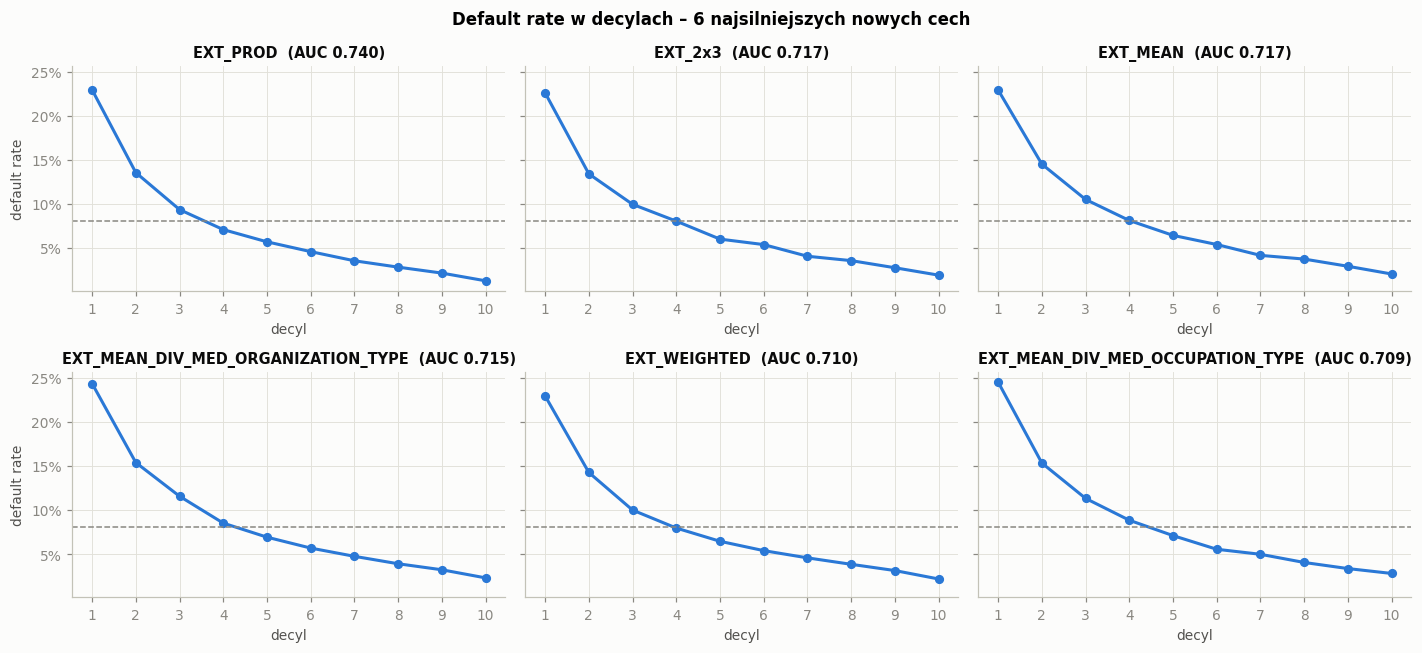

In [13]:
top_new = qc.head(6).index.tolist()
fig, axes = plt.subplots(2, 3, figsize=(13, 6), sharey=True)
base_rate = y.mean()
for ax, f in zip(axes.flat, top_new):
    g = y.groupby(pd.qcut(df[f], 10, labels=False, duplicates='drop')).mean()
    ax.plot(g.index + 1, g.values, color=C0, lw=2, marker='o', ms=5)
    ax.axhline(base_rate, color=MUTED, ls='--', lw=1)
    ax.set_title(f'{f}  (AUC {qc.loc[f, "AUC_jednowym."]:.3f})', fontsize=9.5)
    ax.set_xticks(range(1, 11)); ax.set_xlabel('decyl')
for ax in axes[:, 0]:
    ax.yaxis.set_major_formatter(mtick.PercentFormatter(1, decimals=0)); ax.set_ylabel('default rate')
fig.suptitle('Default rate w decylach – 6 najsilniejszych nowych cech', fontweight='bold')
plt.tight_layout(); plt.show()

## 4. Redukcja

- Kolumny prawie stałe (dominująca wartość > 99,5%) – głównie `FLAG_MOBIL` i rzadkie `FLAG_DOCUMENT_*` (ich informacja zostaje w `DOC_COUNT`).
- Blok budynkowy: warianty `_MODE` i `_MEDI` są niemal identyczne z `_AVG` (|r| > 0,98) – zostawiamy tylko `_AVG`.
- Pozostałe pary z |r| > 0,99 – usuwamy jedną z nich (tę o niższym AUC jednowymiarowym).

In [14]:
def find_near_constant(df, thr=0.995):
    dom = df.apply(lambda s: s.value_counts(normalize=True, dropna=False).iloc[0])
    return dom[dom > thr].index.tolist()

near_const = [c for c in find_near_constant(df) if c not in ('SK_ID_CURR', 'TARGET')]
mode_medi = [c for c in BUILDING_COLS if c.endswith(('_MODE', '_MEDI'))]
drop_1 = sorted(set(near_const) | set(mode_medi))
print(f'Prawie stałe ({len(near_const)}): {near_const}')
print(f'_MODE/_MEDI: {len(mode_medi)} kolumn')

num = df.drop(columns=drop_1 + ['SK_ID_CURR', 'TARGET']).select_dtypes('number')
corr = num.sample(100_000, random_state=SEED).corr().abs()
upper = corr.where(np.triu(np.ones(corr.shape, dtype=bool), k=1))
pairs = upper.stack().loc[lambda s: s > 0.99]
auc_cache = {}
def auc_of(c):
    if c not in auc_cache:
        auc_cache[c] = uni_auc(df[c], y)
    return auc_cache[c]
# Zachłannie, od najsilniej skorelowanych par. Pomijamy pary, w których coś już usunięto (inaczej łańcuch
# DAYS_BIRTH–AGE_YEARS–CREDIT_END_AGE wyciąłby wszystkie trzy). Przy parze oryginał vs nowa cecha zostawiamy
# oryginał (interpretowalność), w pozostałych – cechę o wyższym AUC jednowymiarowym.
drop_corr = set()
for (a, b), _ in pairs.sort_values(ascending=False).items():
    if a in drop_corr or b in drop_corr:
        continue
    a_new, b_new = a in new_cols, b in new_cols
    if a_new != b_new:
        drop_corr.add(a if a_new else b)
    else:
        drop_corr.add(a if auc_of(a) < auc_of(b) else b)
drop_corr = sorted(drop_corr)
print(f'\nPary |r| > 0.99: {len(pairs)}  →  usuwane: {drop_corr}')
display(pairs.to_frame('|r|'))

DROP = sorted(set(drop_1) | set(drop_corr))
df = df.drop(columns=DROP)
print(f'\nUsunięto {len(DROP)} kolumn  →  {df.shape[1]} kolumn')

Prawie stałe (16): ['FLAG_MOBIL', 'FLAG_CONT_MOBILE', 'FLAG_DOCUMENT_2', 'FLAG_DOCUMENT_4', 'FLAG_DOCUMENT_7', 'FLAG_DOCUMENT_9', 'FLAG_DOCUMENT_10', 'FLAG_DOCUMENT_11', 'FLAG_DOCUMENT_12', 'FLAG_DOCUMENT_13', 'FLAG_DOCUMENT_14', 'FLAG_DOCUMENT_15', 'FLAG_DOCUMENT_17', 'FLAG_DOCUMENT_19', 'FLAG_DOCUMENT_20', 'FLAG_DOCUMENT_21']
_MODE/_MEDI: 29 kolumn



Pary |r| > 0.99: 9  →  usuwane: ['AGE_YEARS', 'AMT_CREDIT_DIV_MED_NAME_INCOME_TYPE', 'ANNUITY_INCOME_RATIO_DIV_MED_NAME_EDUCATION_TYPE', 'CREDIT_END_AGE', 'EMPLOYED_YEARS', 'EXT_MEAN_DIV_MED_ORGANIZATION_TYPE', 'FLAG_EMP_PHONE', 'OBS_60_CNT_SOCIAL_CIRCLE']


|r|
AMT_CREDIT               AMT_CREDIT_DIV_MED_NAME_INCOME_TYPE              0.9923
DAYS_BIRTH               AGE_YEARS                                        1.0000
                         CREDIT_END_AGE                                   0.9986
DAYS_EMPLOYED            EMPLOYED_YEARS                                   1.0000
FLAG_EMP_PHONE           DAYS_EMPLOYED_ANOM                               0.9999
OBS_30_CNT_SOCIAL_CIRCLE OBS_60_CNT_SOCIAL_CIRCLE                         0.9983
EXT_MEAN                 EXT_MEAN_DIV_MED_ORGANIZATION_TYPE               0.9953
ANNUITY_INCOME_RATIO     ANNUITY_INCOME_RATIO_DIV_MED_NAME_EDUCATION_TYPE 0.9939
AGE_YEARS                CREDIT_END_AGE                                   0.9986


Usunięto 53 kolumn  →  120 kolumn


## 5. Kodowanie zmiennych kategorycznych

- Binarne (`FLAG_OWN_CAR`, `FLAG_OWN_REALTY`, `NAME_CONTRACT_TYPE`, `CODE_GENDER`, `EMERGENCYSTATE_MODE`) → 0/1.
- Pozostałe → typ `category` (LightGBM obsługuje je natywnie, parquet zachowuje typ).
- Dodatkowo frequency encoding dla wysokiej kardynalności (`ORGANIZATION_TYPE`, `OCCUPATION_TYPE`) – liczności z treningu.
- One-hot / target encoding robimy dopiero w pipeline modelu (target encoding tylko wewnątrz CV).

In [15]:
BINARY_MAP = {
    'FLAG_OWN_CAR': {'N': 0, 'Y': 1},
    'FLAG_OWN_REALTY': {'N': 0, 'Y': 1},
    'NAME_CONTRACT_TYPE': {'Cash loans': 0, 'Revolving loans': 1},
    'CODE_GENDER': {'F': 0, 'M': 1},
    'EMERGENCYSTATE_MODE': {'No': 0, 'Yes': 1},
}
FREQ_COLS = ['ORGANIZATION_TYPE', 'OCCUPATION_TYPE']

def fit_encoders(df):
    cat_cols = [c for c in df.select_dtypes('object').columns if c not in BINARY_MAP]
    return {
        'categories': {c: sorted(df[c].dropna().unique().tolist()) for c in cat_cols},
        'freq': {c: df[c].value_counts(normalize=True).to_dict() for c in FREQ_COLS},
    }

def encode(df, enc):
    df = df.copy()
    for c, m in BINARY_MAP.items():
        df[c] = df[c].map(m).astype('float32')        # float, bo mogą być NaN
    for c in FREQ_COLS:
        df[f'{c}_FREQ'] = df[c].map(enc['freq'][c]).astype(float)
    for c, cats in enc['categories'].items():
        df[c] = pd.Categorical(df[c], categories=cats)   # nieznane w teście kategorie → NaN
    return df

encoders = fit_encoders(df)
df = encode(df, encoders)
print('Zmienne kategoryczne (category):', list(encoders['categories']))
print('Pozostałe kolumny object:', df.select_dtypes('object').columns.tolist())

Zmienne kategoryczne (category): ['NAME_TYPE_SUITE', 'NAME_INCOME_TYPE', 'NAME_EDUCATION_TYPE', 'NAME_FAMILY_STATUS', 'NAME_HOUSING_TYPE', 'OCCUPATION_TYPE', 'WEEKDAY_APPR_PROCESS_START', 'ORGANIZATION_TYPE', 'FONDKAPREMONT_MODE', 'HOUSETYPE_MODE', 'WALLSMATERIAL_MODE']
Pozostałe kolumny object: []


In [16]:
# Zmniejszenie pamięci: float64 → float32, int64 → najmniejszy pasujący int
def downcast(df):
    for c in df.select_dtypes('float64').columns:
        df[c] = df[c].astype('float32')
    for c in df.select_dtypes('int64').columns:
        if c != 'SK_ID_CURR':
            df[c] = pd.to_numeric(df[c], downcast='integer')
    return df

mb_before = df.memory_usage(deep=True).sum() / 1024**2
df = downcast(df)
print(f'Pamięć: {mb_before:,.0f} MB → {df.memory_usage(deep=True).sum() / 1024**2:,.0f} MB')
print(f'Finalny zbiór: {df.shape[0]:,} × {df.shape[1]} (w tym SK_ID_CURR i TARGET)')
print()
print(df.dtypes.map(lambda t: t.name).value_counts().to_string())

Pamięć: 240 MB → 107 MB
Finalny zbiór: 307,511 × 122 (w tym SK_ID_CURR i TARGET)

float32     78
int8        29
category    11
int16        3
int64        1


## 6. Walidacja: AUC przed i po inżynierii cech

In [17]:
X_fe = df.drop(columns=['SK_ID_CURR', 'TARGET'])
res_fe = cv_lgb(X_fe, y)

summary = pd.DataFrame({
    'liczba cech': [raw.shape[1] - 2, X_fe.shape[1]],
    'OOF AUC': [res_base['oof_auc'], res_fe['oof_auc']],
    'AUC średnia z foldów': [res_base['fold_auc'].mean(), res_fe['fold_auc'].mean()],
    'AUC std': [res_base['fold_auc'].std(), res_fe['fold_auc'].std()],
}, index=['surowe dane', 'po feature engineering'])
display(summary)
print(f"Zmiana OOF AUC: {res_fe['oof_auc'] - res_base['oof_auc']:+.4f}")
# Ten sam podział na foldy w obu przebiegach → porównanie parami
delta = res_fe['fold_auc'] - res_base['fold_auc']
print('Zmiana AUC w każdym foldzie:', np.round(delta, 4), f'→ poprawa w {(delta > 0).sum()}/5 foldach')

,liczba cech,OOF AUC,AUC średnia z foldów,AUC std
surowe dane,120,0.7598,0.7598,0.0042
po feature engineering,120,0.7688,0.7689,0.0043


Zmiana OOF AUC: +0.0090
Zmiana AUC w każdym foldzie: [0.0089 0.0092 0.0072 0.0095 0.0104] → poprawa w 5/5 foldach


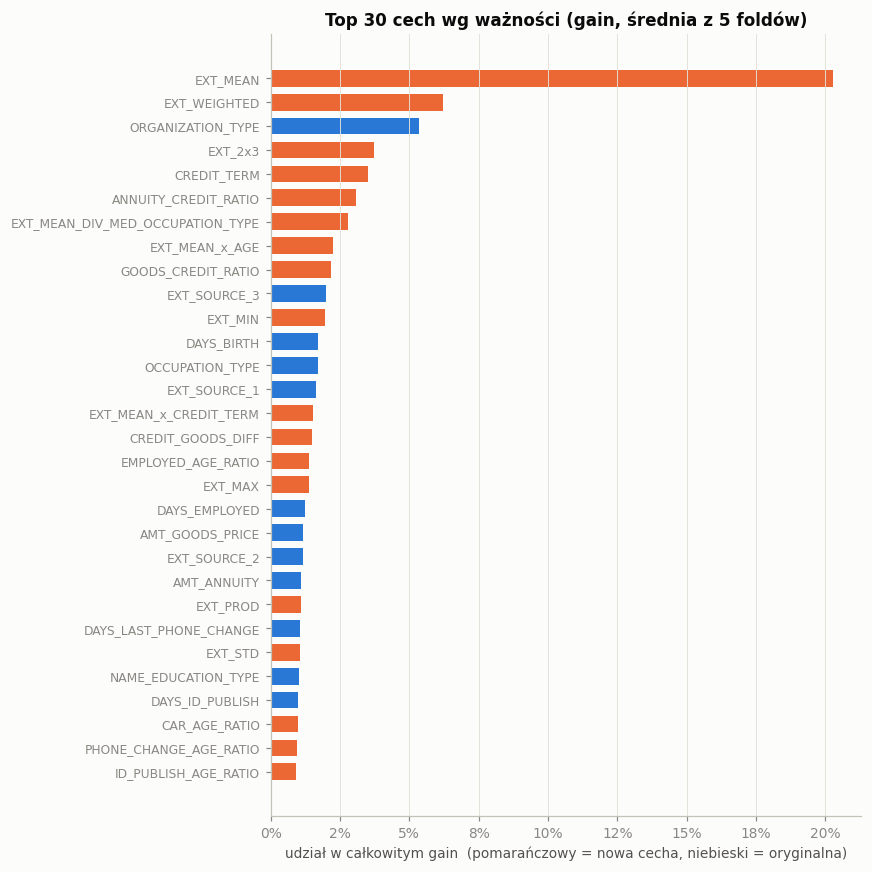

Nowe cechy w top 30: 18
Udział nowych cech w całkowitym gain: 66.9%


In [18]:
imp = res_fe['importance']
imp_share = imp / imp.sum()
top30 = imp_share.head(30)
is_new = [c in new_cols or c.endswith('_FREQ') for c in top30.index]

fig, ax = plt.subplots(figsize=(8, 8))
ax.barh(top30.index[::-1], top30.values[::-1], height=0.7,
        color=[C1 if n else C0 for n in is_new[::-1]])
ax.xaxis.set_major_formatter(mtick.PercentFormatter(1, decimals=0))
ax.set_title('Top 30 cech wg ważności (gain, średnia z 5 foldów)')
ax.set_xlabel('udział w całkowitym gain  (pomarańczowy = nowa cecha, niebieski = oryginalna)')
ax.grid(axis='y', visible=False); ax.tick_params(axis='y', labelsize=8)
plt.tight_layout(); plt.show()

print(f'Nowe cechy w top 30: {sum(is_new)}')
print(f'Udział nowych cech w całkowitym gain: {imp_share[[c for c in imp_share.index if c in new_cols or c.endswith("_FREQ")]].sum():.1%}')

In [19]:
# Cechy, z których model praktycznie nie korzysta – kandydaci do usunięcia w kolejnej iteracji
useless = imp_share[imp_share < 1e-4]
print(f'Cechy z udziałem gain < 0.01%: {len(useless)}')
print(useless.index.tolist())

Cechy z udziałem gain < 0.01%: 8
['LIVE_REGION_NOT_WORK_REGION', 'REG_REGION_NOT_LIVE_REGION', 'FLAG_DOCUMENT_6', 'OCCUPATION_MISSING', 'FLAG_DOCUMENT_16', 'BUREAU_MISSING', 'FLAG_DOCUMENT_18', 'DAYS_EMPLOYED_ANOM']


## 7. Zapis

In [20]:
df.to_parquet(OUT / 'train_fe.parquet', index=False)

feature_list = {
    'features': X_fe.columns.tolist(),
    'categorical': list(encoders['categories']),
    'new_features': [c for c in X_fe.columns if c in new_cols or c.endswith('_FREQ')],
    'dropped': DROP,
}
(OUT / 'feature_list.json').write_text(json.dumps(feature_list, indent=2, ensure_ascii=False), encoding='utf-8')

# Wszystko, co zostało „wyuczone” na treningu i musi być użyte 1:1 na zbiorze testowym
artifacts = {'clip_bounds': clip_bounds, 'group_stats': group_stats, 'encoders': encoders, 'drop': DROP}
(OUT / 'fe_artifacts.json').write_text(json.dumps(artifacts, ensure_ascii=False, default=float), encoding='utf-8')

for p in sorted(OUT.iterdir()):
    print(f'{p}  ({p.stat().st_size / 1024**2:,.1f} MB)')

# Kontrola: odczyt zachowuje typy kategoryczne
chk = pd.read_parquet(OUT / 'train_fe.parquet')
assert chk.shape == df.shape and (chk.dtypes == df.dtypes).all()
print('\nOdczyt OK:', chk.shape)

data\processed\fe_artifacts.json  (0.0 MB)
data\processed\feature_list.json  (0.0 MB)
data\processed\train_fe.parquet  (47.1 MB)

Odczyt OK: (307511, 122)


### Jak zastosować to samo do zbioru testowego

```python
art = json.loads((OUT / 'fe_artifacts.json').read_text(encoding='utf-8'))
test = pd.read_csv(DATA / 'application_test.csv')
test = clean(test, art['clip_bounds'])
test, _ = build_features(test, group_stats=art['group_stats'])
test = test.drop(columns=art['drop'], errors='ignore')
test = downcast(encode(test, art['encoders']))
```

## 8. Podsumowanie

### Wynik
| | liczba cech | OOF AUC (LightGBM, 5-fold) |
|---|---|---|
| surowe dane | 120 | 0,7598 |
| po feature engineering | 120 | **0,7688** |

**+0,009 AUC** przy tej samej liczbie cech, z poprawą w każdym z 5 foldów (+0,007…+0,010). Podział na foldy był identyczny w obu przebiegach, więc to porównanie parami, a nie szum.

### Co zostało zrobione
- **Czyszczenie:** `DAYS_EMPLOYED = 365243` → NaN + flaga; `XNA`/`Unknown` → NaN; `DAYS_LAST_PHONE_CHANGE = 0` → NaN; przycięcie outlierów (dochód, social circle, zapytania BIK, dzieci) do p99,9.
- **50 nowych cech** w 6 grupach: agregaty `EXT_SOURCE`, ratio finansowe, cechy czasowe, liczniki flag/dokumentów/zapytań, liczniki braków, cechy grupowe (wartość / mediana w grupie).
- **Redukcja o 53 kolumny:** 16 prawie stałych flag, 29 duplikatów `_MODE/_MEDI` z bloku budynkowego, 8 kolumn z par |r| > 0,99.
- **Kodowanie:** 5 zmiennych binarnych → 0/1, 11 kategorycznych → `category`, frequency encoding dla `ORGANIZATION_TYPE` i `OCCUPATION_TYPE`.
- **Pamięć:** 240 MB → 107 MB (float32 / int8).

### Obserwacje
- Nowe cechy dają **~67% całkowitego gain** modelu i zajmują 18 z top 30 miejsc.
- `EXT_MEAN` jest zdecydowanie najważniejszą cechą (~20% gain), dalej `EXT_WEIGHTED`, `ORGANIZATION_TYPE`, `EXT_2x3`, `CREDIT_TERM` i `ANNUITY_CREDIT_RATIO`. Model najbardziej korzysta z różnych kombinacji zewnętrznych scoringów.
- `CREDIT_TERM` / `ANNUITY_CREDIT_RATIO` są jednowymiarowo słabe (AUC 0,53), ale w modelu trafiają do top 6, bo działają w interakcji z innymi cechami.
- `EXT_PROD` ma najwyższe AUC jednowymiarowe (0,74), ale jest liczone tylko na 36% wierszy (tam, gdzie są wszystkie 3 scoringi), więc nie można go porównywać wprost z pozostałymi.
- Cechy grupowe działają głównie dla `EXT_MEAN` (względem zawodu). Dochód i kredyt względem grupy wnoszą niewiele.
- Model prawie nie korzysta z 8 cech (gain < 0,01%), m.in. `DAYS_EMPLOYED_ANOM` (tę samą informację niesie NaN w `DAYS_EMPLOYED`), `BUREAU_MISSING`, `OCCUPATION_MISSING` i rzadkich `FLAG_DOCUMENT_*`. Można je usunąć w kolejnej iteracji.

### Następne kroki
1. **Modelowanie:** tuning hiperparametrów LightGBM (Optuna), target encoding `ORGANIZATION_TYPE` wewnątrz CV, porównanie z regresją logistyczną (wymaga one-hot + imputacji + skalowania).
2. **Więcej danych:** agregaty z `bureau.csv`, `previous_application.csv`, `installments_payments.csv` itp. W tym konkursie to one dają największy skok (do ~0,79 AUC).
3. **Selekcja cech:** usunąć cechy z zerowym gain, sprawdzić permutation importance / SHAP.